In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load Data

In [2]:
df_awal = pd.read_csv('WA_Fn-UseC_-Telco-Customer-Churn.csv')
df_awal

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7038,6840-RESVB,Male,0,Yes,Yes,24,Yes,Yes,DSL,Yes,...,Yes,Yes,Yes,Yes,One year,Yes,Mailed check,84.80,1990.5,No
7039,2234-XADUH,Female,0,Yes,Yes,72,Yes,Yes,Fiber optic,No,...,Yes,No,Yes,Yes,One year,Yes,Credit card (automatic),103.20,7362.9,No
7040,4801-JZAZL,Female,0,Yes,Yes,11,No,No phone service,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.60,346.45,No
7041,8361-LTMKD,Male,1,Yes,No,4,Yes,Yes,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Mailed check,74.40,306.6,Yes


In [3]:
kolom = [
    "PhoneService",
    "MultipleLines",
    "InternetService",
    "OnlineSecurity",
    "OnlineBackup",
    "DeviceProtection",
    "TechSupport",
    "StreamingTV",
    "StreamingMovies",
    'Churn'
]
df = df_awal[kolom]
df

,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Churn
0,No,No phone service,DSL,No,Yes,No,No,No,No,No
1,Yes,No,DSL,Yes,No,Yes,No,No,No,No
2,Yes,No,DSL,Yes,Yes,No,No,No,No,Yes
3,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,No
4,Yes,No,Fiber optic,No,No,No,No,No,No,Yes
...,...,...,...,...,...,...,...,...,...,...
7038,Yes,Yes,DSL,Yes,No,Yes,Yes,Yes,Yes,No
7039,Yes,Yes,Fiber optic,No,Yes,Yes,No,Yes,Yes,No
7040,No,No phone service,DSL,Yes,No,No,No,No,No,No
7041,Yes,Yes,Fiber optic,No,No,No,No,No,No,Yes


# Cek Kualitas Data

In [4]:
# Missing Value
df.isna().sum()

PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Churn               0
dtype: int64

In [5]:
# duplikat
df.duplicated().sum()

np.int64(6485)

In [6]:
# Cek Unique
print(df[kolom].nunique())
print('\n'*5)

for c in kolom:
    print(df[c].unique())
    print(df[c].value_counts())
    print()

PhoneService        2
MultipleLines       3
InternetService     3
OnlineSecurity      3
OnlineBackup        3
DeviceProtection    3
TechSupport         3
StreamingTV         3
StreamingMovies     3
Churn               2
dtype: int64






<StringArray>
['No', 'Yes']
Length: 2, dtype: str
PhoneService
Yes    6361
No      682
Name: count, dtype: int64

<StringArray>
['No phone service', 'No', 'Yes']
Length: 3, dtype: str
MultipleLines
No                  3390
Yes                 2971
No phone service     682
Name: count, dtype: int64

<StringArray>
['DSL', 'Fiber optic', 'No']
Length: 3, dtype: str
InternetService
Fiber optic    3096
DSL            2421
No             1526
Name: count, dtype: int64

<StringArray>
['No', 'Yes', 'No internet service']
Length: 3, dtype: str
OnlineSecurity
No                     3498
Yes                    2019
No internet service    1526
Name: count, dtype: int64

<StringArray>
['Yes', 'No', 'No internet service']
Length: 3, dtype: str
OnlineBackup
No      

In [7]:
# cek hidden value
for i in kolom:
    print(
        (df[i].str.strip() == '').sum()
    )

0
0
0
0
0
0
0
0
0
0


In [8]:
# cek konsistensi antar kolom
pd.crosstab(df['PhoneService'], df['MultipleLines'])

MultipleLines,No,No phone service,Yes
PhoneService,,,
No,0,682,0
Yes,3390,0,2971


In [9]:
addon = ['OnlineSecurity','OnlineBackup','DeviceProtection','TechSupport','StreamingTV','StreamingMovies']
for c in addon:
    display(pd.crosstab(df['InternetService'], df[c]))

OnlineSecurity,No,No internet service,Yes
InternetService,,,
DSL,1241,0,1180
Fiber optic,2257,0,839
No,0,1526,0


OnlineBackup,No,No internet service,Yes
InternetService,,,
DSL,1335,0,1086
Fiber optic,1753,0,1343
No,0,1526,0


DeviceProtection,No,No internet service,Yes
InternetService,,,
DSL,1356,0,1065
Fiber optic,1739,0,1357
No,0,1526,0


TechSupport,No,No internet service,Yes
InternetService,,,
DSL,1243,0,1178
Fiber optic,2230,0,866
No,0,1526,0


StreamingTV,No,No internet service,Yes
InternetService,,,
DSL,1464,0,957
Fiber optic,1346,0,1750
No,0,1526,0


StreamingMovies,No,No internet service,Yes
InternetService,,,
DSL,1440,0,981
Fiber optic,1345,0,1751
No,0,1526,0


# Analisis Univariat

In [10]:
# Frekuensi dan Proporsi
for c in kolom:
    tabel = pd.concat([df[c].value_counts(),df[c].value_counts(normalize=True)],axis=1, keys=['jumlah', 'rasio'])
    display(tabel)

,jumlah,rasio
PhoneService,,
Yes,6361,0.903166
No,682,0.096834


,jumlah,rasio
MultipleLines,,
No,3390,0.481329
Yes,2971,0.421837
No phone service,682,0.096834


,jumlah,rasio
InternetService,,
Fiber optic,3096,0.439585
DSL,2421,0.343746
No,1526,0.216669


,jumlah,rasio
OnlineSecurity,,
No,3498,0.496663
Yes,2019,0.286668
No internet service,1526,0.216669


,jumlah,rasio
OnlineBackup,,
No,3088,0.438450
Yes,2429,0.344881
No internet service,1526,0.216669


,jumlah,rasio
DeviceProtection,,
No,3095,0.439443
Yes,2422,0.343888
No internet service,1526,0.216669


,jumlah,rasio
TechSupport,,
No,3473,0.493114
Yes,2044,0.290217
No internet service,1526,0.216669


,jumlah,rasio
StreamingTV,,
No,2810,0.398978
Yes,2707,0.384353
No internet service,1526,0.216669


,jumlah,rasio
StreamingMovies,,
No,2785,0.395428
Yes,2732,0.387903
No internet service,1526,0.216669


,jumlah,rasio
Churn,,
No,5174,0.73463
Yes,1869,0.26537


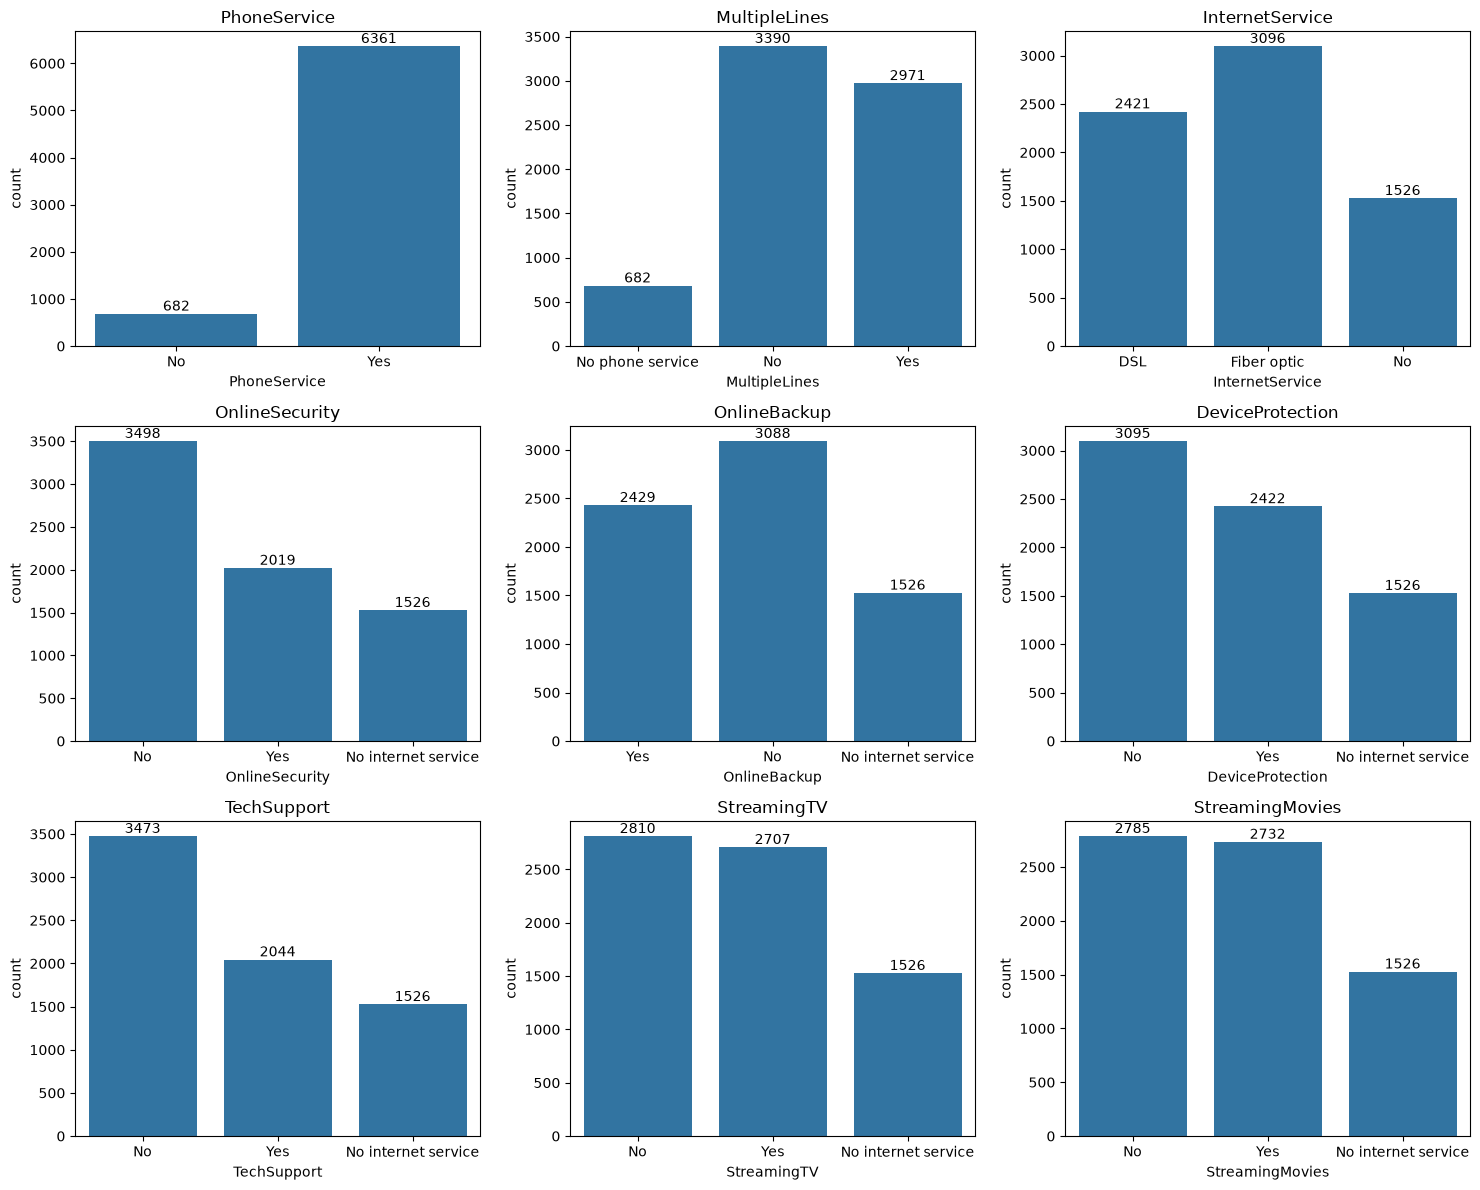

In [11]:
# visualisasi
fig, axes = plt.subplots(3, 3, figsize=(15, 12))

for ax, c in zip(axes.flat, kolom):
    sns.countplot(
        data=df,
        x=c,ax=ax
    )
    ax.set_title(c)
    ax.bar_label(ax.containers[0])
plt.tight_layout()
plt.show()

## Kesimpulan Analisis Univariat

Total data: **7043 pelanggan**.

**1. Layanan Telepon**
- **PhoneService** sangat timpang: 90.3% pelanggan menggunakan layanan telepon, hanya 9.7% yang tidak. Variasi kolom ini kecil sehingga kemungkinan kurang informatif.
- **MultipleLines**: 48.1% tidak menggunakan, 42.2% menggunakan, dan 9.7% tidak memiliki layanan telepon.

**2. Layanan Internet**
- **InternetService**: Fiber optic paling banyak digunakan (44.0%), diikuti DSL (34.4%). Sebanyak 21.7% pelanggan tidak memiliki layanan internet.

**3. Layanan Tambahan (Add-on)**
- Kategori `No internet service` memiliki proporsi yang sama (21.7%) di keenam kolom add-on karena berasal dari kelompok pelanggan yang sama.
- **OnlineSecurity** (28.7%) dan **TechSupport** (29.0%) merupakan add-on yang paling jarang digunakan.
- **OnlineBackup** (34.5%) dan **DeviceProtection** (34.4%) memiliki tingkat penggunaan yang hampir sama.
- **StreamingTV** (38.4%) dan **StreamingMovies** (38.8%) memiliki proporsi Yes dan No yang hampir seimbang.

---

# Ketergantungan Antar Kolom

In [12]:
tanpa_internet = df[df['InternetService'] == 'No']
print((tanpa_internet[addon] == 'No internet service').all())

OnlineSecurity      True
OnlineBackup        True
DeviceProtection    True
TechSupport         True
StreamingTV         True
StreamingMovies     True
dtype: bool


In [13]:
tanpa_phone = df[df['PhoneService'] == 'No']
print((tanpa_phone['MultipleLines'] == 'No phone service').all())

True


# Interpretasi 

Artinya:

```text
Output pertama: keenam add-on bernilai True. Semua 1526 pelanggan tanpa internet tercatat “No internet service” di semua add-on, tanpa pengecualian.
Output kedua: True. Semua 682 pelanggan tanpa telepon tercatat “No phone service” di MultipleLines.
```

Kesimpulannya, ketergantungannya pasti dan datanya konsisten.

---

# Analisis Bivariat

In [14]:
df_awal['Churn'].value_counts(normalize=True)

Churn
No     0.73463
Yes    0.26537
Name: proportion, dtype: float64

In [18]:
for c in kolom:
    tabel = pd.crosstab(df[c], df_awal['Churn'], normalize='index')
    display(tabel)

Churn,No,Yes
PhoneService,,
No,0.750733,0.249267
Yes,0.732904,0.267096


Churn,No,Yes
MultipleLines,,
No,0.749558,0.250442
No phone service,0.750733,0.249267
Yes,0.713901,0.286099


Churn,No,Yes
InternetService,,
DSL,0.810409,0.189591
Fiber optic,0.581072,0.418928
No,0.925950,0.074050


Churn,No,Yes
OnlineSecurity,,
No,0.582333,0.417667
No internet service,0.925950,0.074050
Yes,0.853888,0.146112


Churn,No,Yes
OnlineBackup,,
No,0.600712,0.399288
No internet service,0.925950,0.074050
Yes,0.784685,0.215315


Churn,No,Yes
DeviceProtection,,
No,0.608724,0.391276
No internet service,0.925950,0.074050
Yes,0.774979,0.225021


Churn,No,Yes
TechSupport,,
No,0.583645,0.416355
No internet service,0.925950,0.074050
Yes,0.848337,0.151663


Churn,No,Yes
StreamingTV,,
No,0.664769,0.335231
No internet service,0.925950,0.074050
Yes,0.699298,0.300702


Churn,No,Yes
StreamingMovies,,
No,0.663196,0.336804
No internet service,0.925950,0.074050
Yes,0.700586,0.299414


Churn,No,Yes
Churn,,
No,1.0,0.0
Yes,0.0,1.0


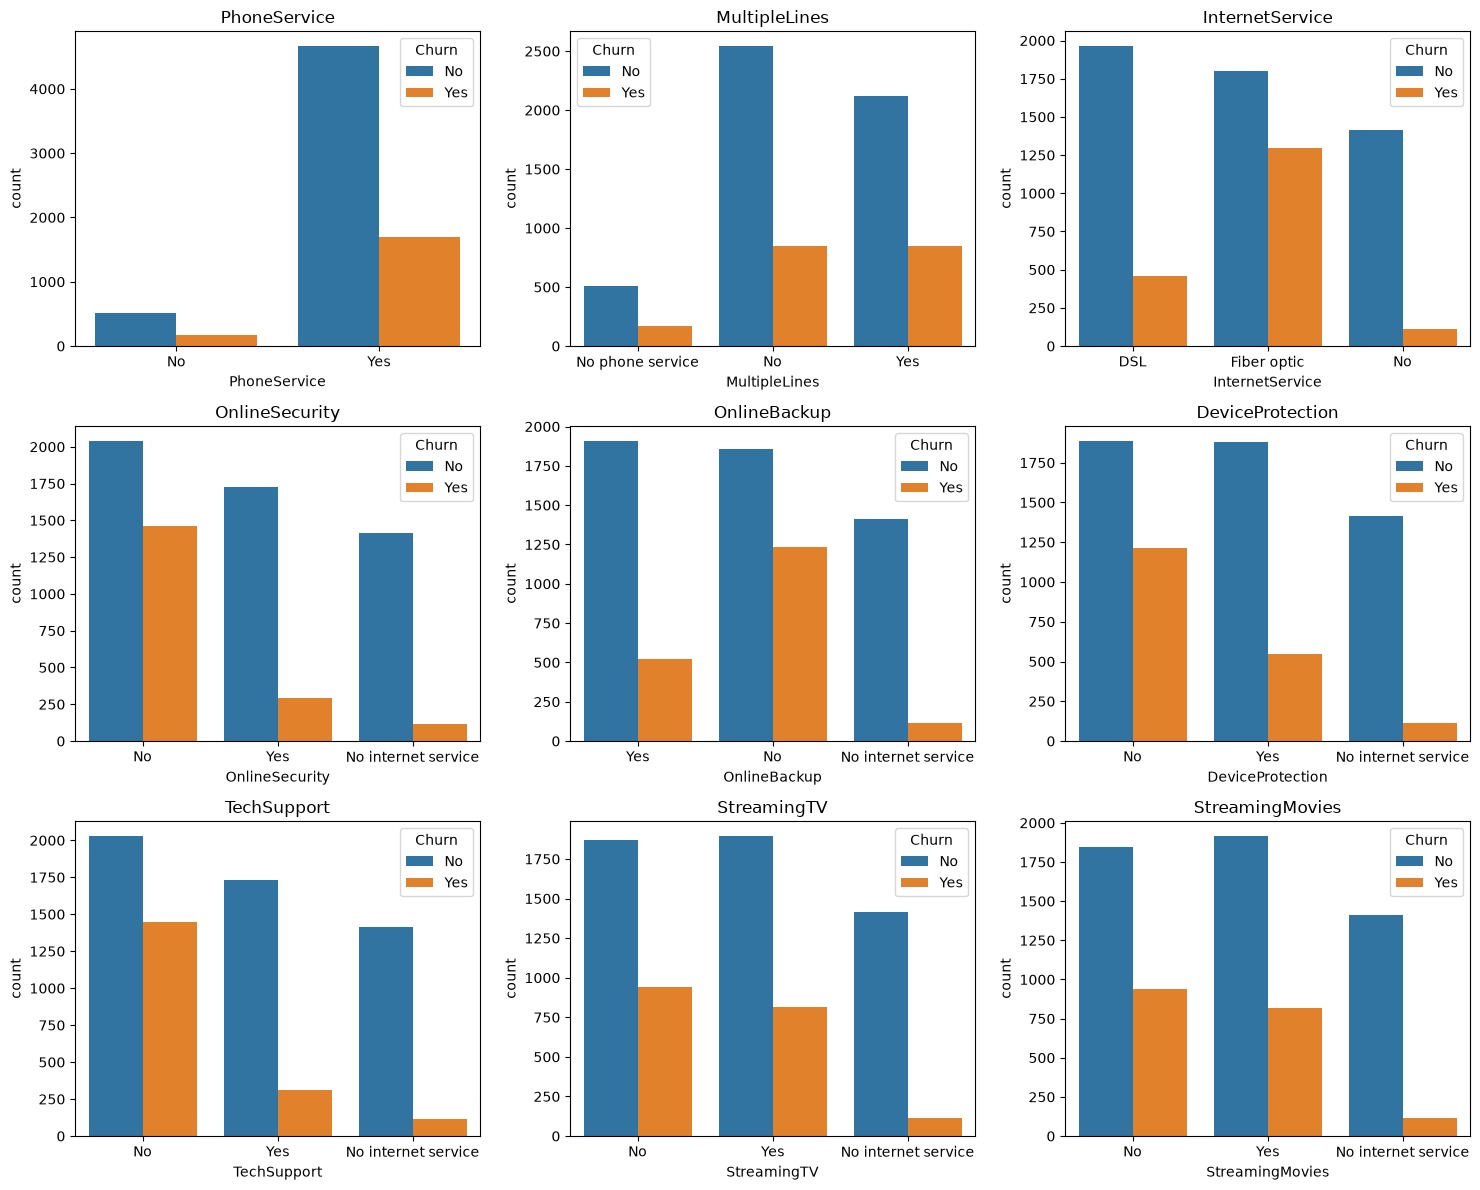

In [19]:
fig, axes = plt.subplots(3, 3, figsize=(15, 12))

for ax, c in zip(axes.flat, kolom):
    sns.countplot(
        data=df,
        x=c,
        hue='Churn',
        ax=ax
    )
    ax.set_title(c)
plt.tight_layout()
plt.show()

### Kesimpulan Analisis Bivariat terhadap Churn

Baseline churn rate seluruh pelanggan: **26.5%**.

**1. Pengaruh kuat**
- **InternetService**: churn pelanggan Fiber optic sangat tinggi (41.9%), DSL 19.0%, dan pelanggan tanpa internet hanya 7.4%.
- **OnlineSecurity**: churn pelanggan yang tidak menggunakan 41.8%, sedangkan yang menggunakan hanya 14.6%.
- **TechSupport**: churn pelanggan yang tidak menggunakan 41.6%, sedangkan yang menggunakan hanya 15.2%.

**2. Pengaruh sedang**
- **OnlineBackup**: tidak menggunakan 39.9% vs menggunakan 21.5%.
- **DeviceProtection**: tidak menggunakan 39.1% vs menggunakan 22.5%.

**3. Pengaruh lemah**
- **StreamingTV** (33.5% vs 30.1%) dan **StreamingMovies** (33.7% vs 29.9%): perbedaan churn kecil.
- **MultipleLines**: No 25.0%, Yes 28.6%, No phone service 24.9%, semuanya mendekati baseline.
- **PhoneService**: No 24.9% vs Yes 26.7%, hampir tidak ada perbedaan.

**Catatan:**
- Churn rendah pada kategori `No internet service` (7.4%) disebabkan oleh tidak adanya layanan internet, bukan karena tidak menggunakan add-on (lihat tahap Ketergantungan Antar Kolom).
- Add-on bersifat proteksi/dukungan (OnlineSecurity, TechSupport) memiliki hubungan paling kuat dengan churn yang lebih rendah.
- Hasil ini menunjukkan hubungan, bukan sebab-akibat. Kekuatan hubungan akan diuji secara statistik pada tahap berikutnya.

---

# Uji Statsitik

In [20]:
from scipy.stats import chi2_contingency
import numpy as np

hasil = []
for c in kolom:
    tabel = pd.crosstab(df[c], df['Churn'])
    chi2, p, dof, _ = chi2_contingency(tabel)
    n = tabel.values.sum()
    v = np.sqrt(chi2 / (n * (min(tabel.shape) - 1)))
    hasil.append([c, round(chi2, 1), p, round(v, 3)])

hasil = pd.DataFrame(hasil, columns=['kolom', 'chi2', 'p_value', 'cramers_v'])
hasil.sort_values('cramers_v', ascending=False)

,kolom,chi2,p_value,cramers_v
9,Churn,7037.9,0.000000e+00,1.000
3,OnlineSecurity,850.0,2.661150e-185,0.347
6,TechSupport,828.2,1.443084e-180,0.343
2,InternetService,732.3,9.571788e-160,0.322
4,OnlineBackup,601.8,2.079759e-131,0.292
5,DeviceProtection,558.4,5.505219e-122,0.282
7,StreamingTV,374.2,5.528994e-82,0.231
8,StreamingMovies,375.7,2.667757e-82,0.231
1,MultipleLines,11.3,3.464383e-03,0.040
0,PhoneService,0.9,3.387825e-01,0.011


### Kesimpulan Uji Statistik

Uji Chi-square digunakan untuk menguji hubungan tiap kolom layanan dengan Churn (H0: tidak ada hubungan, α = 0.05). Kekuatan hubungan diukur dengan Cramér's V (< 0.1 lemah, 0.1–0.3 sedang, > 0.3 kuat).

**Ranking kekuatan hubungan dengan Churn:**

| Ranking | Kolom | Cramér's V | Kategori |
|---|---|---|---|
| 1 | OnlineSecurity | 0.347 | Kuat |
| 2 | TechSupport | 0.343 | Kuat |
| 3 | InternetService | 0.322 | Kuat |
| 4 | OnlineBackup | 0.292 | Sedang |
| 5 | DeviceProtection | 0.282 | Sedang |
| 6 | StreamingTV | 0.231 | Sedang |
| 7 | StreamingMovies | 0.231 | Sedang |
| 8 | MultipleLines | 0.040 | Lemah |
| 9 | PhoneService | 0.011 | Lemah, tidak signifikan |

**Temuan:**
- Delapan kolom berhubungan signifikan dengan Churn (p-value < 0.05). Hanya **PhoneService** yang tidak signifikan (p-value = 0.339).
- **MultipleLines** signifikan, tetapi hubungannya sangat lemah (V = 0.040). Signifikansi ini kemungkinan dipengaruhi jumlah data yang besar.
- **OnlineSecurity, TechSupport, dan InternetService** memiliki hubungan terkuat dengan Churn. Hasil ini konsisten dengan analisis bivariat.
- Nilai Cramér's V pada kolom add-on ikut dipengaruhi oleh kategori `No internet service`, yang berasal dari kolom InternetService (lihat tahap Ketergantungan Antar Kolom).

---

# Rangkuman Insight

**Temuan utama:**
1. **Data bersih dan konsisten.** Tidak ada missing value maupun duplikat pada kolom layanan. Kategori `No phone service` dan `No internet service` konsisten dengan kolom layanan utamanya.
2. **Fiber optic adalah layanan internet paling banyak digunakan (44.0%), tetapi juga memiliki churn tertinggi (41.9%).** Angka ini jauh di atas baseline 26.5%.
3. **Add-on proteksi dan dukungan berhubungan paling kuat dengan churn yang lebih rendah.** Pelanggan yang menggunakan OnlineSecurity (churn 14.6%) dan TechSupport (15.2%) jauh lebih jarang churn dibanding yang tidak menggunakan (sekitar 42%). Keduanya memiliki Cramér's V tertinggi (0.347 dan 0.343).
4. **Add-on streaming berpengaruh lemah.** Perbedaan churn antara pengguna dan non-pengguna StreamingTV/StreamingMovies kecil (sekitar 3–4 poin persen).
5. **Layanan telepon hampir tidak berpengaruh.** PhoneService tidak signifikan (p-value = 0.339) dan MultipleLines memiliki hubungan sangat lemah (V = 0.040).

---

**Implikasi untuk preprocessing dan modeling:**
- Kategori `No internet service` dan `No phone service` digabung menjadi `No` untuk menghindari multikolinearitas, karena informasinya sudah terwakili oleh InternetService dan PhoneService.
- Kolom biner di-encode menjadi 0/1. InternetService (3 kategori) di-encode dengan one-hot encoding (`drop_first=True`).
- PhoneService dan MultipleLines dapat dipertimbangkan untuk dihapus atau diuji ulang pengaruhnya pada model, karena hubungannya dengan Churn sangat lemah.
- Target Churn tidak seimbang (26.5% churn), sehingga perlu diperhatikan saat pembagian data dan evaluasi model.

In [30]:
df_model = df
df_model[kolom] = df_model[kolom].replace({'No internet service': 'No', 'No phone service': 'No'})

In [35]:
def encode_internet(data):
    data = data.copy()
    data['InternetService_Fiber'] = (data['InternetService'] == 'Fiber optic').astype(int)
    data['InternetService_No'] = (data['InternetService'] == 'No').astype(int)
    return data.drop(columns='InternetService')

df_model = encode_internet(df_model)

In [36]:
df_model

,PhoneService,MultipleLines,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Churn,InternetService_Fiber,InternetService_No
0,No,No,No,Yes,No,No,No,No,No,0,0
1,Yes,No,Yes,No,Yes,No,No,No,No,0,0
2,Yes,No,Yes,Yes,No,No,No,No,Yes,0,0
3,No,No,Yes,No,Yes,Yes,No,No,No,0,0
4,Yes,No,No,No,No,No,No,No,Yes,1,0
...,...,...,...,...,...,...,...,...,...,...,...
7038,Yes,Yes,Yes,No,Yes,Yes,Yes,Yes,No,0,0
7039,Yes,Yes,No,Yes,Yes,No,Yes,Yes,No,1,0
7040,No,No,Yes,No,No,No,No,No,No,0,0
7041,Yes,Yes,No,No,No,No,No,No,Yes,1,0
